# Step 1: Data Ingestion & Initial Understanding

The goal of this project is to develop a machine learning model that predicts whether a loan application will be **Approved** or **Rejected** based on applicant, financial, credit, and asset information.

In this step, we will download the dataset, load it into pandas, and perform an initial inspection of its structure and target variable.

In [300]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [301]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download(
    "architsharma01/loan-approval-prediction-dataset"
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Minn Bern\.cache\kagglehub\datasets\architsharma01\loan-approval-prediction-dataset\versions\1


In [302]:
df_raw = pd.read_csv(
    os.path.join(path, "loan_approval_dataset.csv")
)

print("Dataset loaded successfully.")
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]:,}")

Dataset loaded successfully.
Rows    : 4,269
Columns : 13


In [303]:
# Column information
print(f"{'#':<5} {'Column':<30} {'Dtype':<15}")

for i, (col, dtype) in enumerate(df_raw.dtypes.items(), 1):
    print(f"{i:<5} {col:<30} {str(dtype):<15}")

#     Column                         Dtype          
1     loan_id                        int64          
2      no_of_dependents              int64          
3      education                     str            
4      self_employed                 str            
5      income_annum                  int64          
6      loan_amount                   int64          
7      loan_term                     int64          
8      cibil_score                   int64          
9      residential_assets_value      int64          
10     commercial_assets_value       int64          
11     luxury_assets_value           int64          
12     bank_asset_value              int64          
13     loan_status                   str            


In [304]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [305]:
df_raw.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [306]:
df_raw.sample(10, random_state=42)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
1703,1704,5,Graduate,No,5400000,19700000,20,423,6500000,10000000,15700000,7300000,Rejected
1173,1174,2,Graduate,No,5900000,14000000,8,599,4700000,9500000,17800000,6700000,Approved
308,309,3,Graduate,No,9600000,19900000,14,452,4200000,16200000,28500000,6600000,Rejected
1322,1323,2,Graduate,No,6200000,23400000,8,605,10000000,10800000,21800000,9200000,Approved
3271,3272,3,Not Graduate,Yes,5800000,14100000,12,738,11700000,4400000,15400000,8400000,Approved
3539,3540,4,Graduate,Yes,4700000,12500000,8,678,13700000,200000,9800000,7000000,Approved
1522,1523,4,Graduate,No,3400000,13500000,12,705,10000000,1100000,8300000,4900000,Approved
3399,3400,5,Not Graduate,Yes,5100000,13700000,14,527,12100000,8900000,19400000,4700000,Rejected
1402,1403,3,Graduate,Yes,3300000,8500000,12,586,7500000,5100000,7800000,3900000,Approved
1829,1830,1,Not Graduate,Yes,3000000,6000000,16,518,3800000,1700000,11600000,3900000,Rejected


### Identify the Target Variable

For this project, the target is `loan_status`, which indicates whether a loan application was **Approved** or **Rejected**.


In [307]:
# ── Clean column names ───────────────────────────────────
df_raw.columns = df_raw.columns.str.strip()

# Identify the target variable
TARGET = "loan_status"

print("Target variable:", TARGET)
print("\nTarget values:")
print(df_raw[TARGET].unique())

Target variable: loan_status

Target values:
<StringArray>
[' Approved', ' Rejected']
Length: 2, dtype: str


### Inspect Target Distribution

We examine how many applications belong to each loan-status class.

This is important because an imbalanced target can affect model training and evaluation. The class distribution will help us decide which evaluation metrics are appropriate later.


In [308]:
target_counts = df_raw[TARGET].value_counts()
target_percent = df_raw[TARGET].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percent.round(2)
})

display(target_summary)

,count,percentage
loan_status,,
Approved,2656,62.22
Rejected,1613,37.78


### Step 1 Summary

We have downloaded and loaded the loan approval dataset and established an initial understanding of its structure, variables, data types, and target variable.

The next step is **Data Quality Investigation**. We will check for missing values, duplicate records, inconsistent categorical values, invalid numerical values, unusual ranges, and other potential problems before making any cleaning decisions.


# Step 2: Data Quality Investigation

Before cleaning the dataset, we need to identify problems that could affect the analysis or machine learning models.

We will check for missing values, duplicates, inconsistent categories, invalid numerical values, unusual ranges, identifier issues, and target validity.

The results from these checks will determine what cleaning actions we take in Step 3.


In [309]:
# ── Missing values ────────────────────────────────────────
missing = df_raw.isnull().sum()

print(f"Total missing values: {missing.sum():,}")

if missing.sum() == 0:
    print("No missing values found.")
else:
    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percent": (missing / len(df_raw) * 100).round(2)
    })

    display(missing_summary[missing_summary["missing_count"] > 0])

Total missing values: 0
No missing values found.


In [310]:
# ── Duplicate records ────────────────────────────────────
duplicate_count = df_raw.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


In [311]:
# ── Categorical values ───────────────────────────────────
categorical_columns = df_raw.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df_raw[col].value_counts(dropna=False))


education
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

self_employed
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

loan_status
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


C:\Users\Minn Bern\AppData\Local\Temp\ipykernel_10080\2048314894.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_raw.select_dtypes(include="object").columns


In [312]:
# ── Numerical summary ────────────────────────────────────
numeric_summary = df_raw.describe().T[
    ["min", "max", "mean", "50%"]
].rename(columns={"50%": "median"})

display(numeric_summary)

,min,max,mean,median
loan_id,1.00,"4,269.00","2,135.00","2,135.00"
no_of_dependents,0.00,5.00,2.50,3.00
income_annum,"200,000.00","9,900,000.00","5,059,123.92","5,100,000.00"
loan_amount,"300,000.00","39,500,000.00","15,133,450.46","14,500,000.00"
loan_term,2.00,20.00,10.90,10.00
cibil_score,300.00,900.00,599.94,600.00
residential_assets_value,"-100,000.00","29,100,000.00","7,472,616.54","5,600,000.00"
commercial_assets_value,0.00,"19,400,000.00","4,973,155.31","3,700,000.00"
luxury_assets_value,"300,000.00","39,200,000.00","15,126,305.93","14,600,000.00"
bank_asset_value,0.00,"14,700,000.00","4,976,692.43","4,600,000.00"


In [313]:
# ── Negative numerical values ────────────────────────────
numeric_columns = df_raw.select_dtypes(include=np.number).columns

negative_counts = (df_raw[numeric_columns] < 0).sum()

display(
    negative_counts[negative_counts > 0]
)

residential_assets_value    28
dtype: int64

### Interpretation

The check identified **28 negative values in `residential_assets_value`**. Since an asset value would normally be expected to be non-negative, these records require further investigation.

We will **not remove them at this stage**. In Step 3, we will inspect these records and decide whether the values should be corrected, treated as invalid, or handled another way. This prevents us from deleting potentially useful observations without understanding the issue.


In [314]:
# ── Loan ID uniqueness ───────────────────────────────────
print(f"Unique loan IDs : {df_raw['loan_id'].nunique():,}")
print(f"Total rows      : {len(df_raw):,}")
print(f"Duplicate IDs   : {df_raw['loan_id'].duplicated().sum():,}")

Unique loan IDs : 4,269
Total rows      : 4,269
Duplicate IDs   : 0


### Validate the Target Variable

The target should contain only the expected loan outcomes.

We verify that the dataset contains only `Approved` and `Rejected` values before moving to the cleaning stage.



In [315]:
# ── Target validation ────────────────────────────────────
valid_targets = {"Approved", "Rejected"}

actual_targets = set(df_raw[TARGET].dropna().unique())

print("Target values found:", actual_targets)
print("Unexpected values:", actual_targets - valid_targets)

Target values found: {' Rejected', ' Approved'}
Unexpected values: {' Rejected', ' Approved'}


### Interpretation

The target contains two expected classes: `Approved` and `Rejected`. However, the raw dataset contains leading whitespace in these values, causing the validation check to initially identify them as unexpected.

This is a **formatting inconsistency rather than a new target class**. The whitespace was normalized during the initial inspection, so the target can be handled consistently during cleaning and modeling.

No invalid target category was identified.


### Step 2 Summary

The data-quality investigation identifies issues that need to be addressed before modeling.

We have checked:

* Missing values
* Duplicate records
* Categorical consistency
* Numerical ranges
* Negative or suspicious values
* Loan identifier uniqueness
* Target validity

The findings from these checks will determine the cleaning operations performed in **Step 3: Data Cleaning**.


### Step 3: Data Cleaning

Now that the data-quality issues have been identified, we can clean the dataset before performing exploratory analysis and modeling.

The cleaning process will:

* Work on a copy of the raw dataset.
* Standardize column names and categorical text.
* Remove duplicate records if any exist.
* Validate the target variable.
* Investigate and handle the negative residential asset values.
* Keep `loan_id` available as an identifier, but exclude it later from model features.



In [316]:
# ── Create cleaned dataset ─────────────────────────────────

df_clean = df_raw.copy()

print(f"Raw dataset shape     : {df_raw.shape}")
print(f"Working dataset shape : {df_clean.shape}")

Raw dataset shape     : (4269, 13)
Working dataset shape : (4269, 13)


In [317]:
# ── Standardize column names and text values ───────────────

df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Text formatting standardized.")
print("\nTarget values after cleaning:")
print(df_clean[TARGET].unique())

C:\Users\Minn Bern\AppData\Local\Temp\ipykernel_10080\2991257691.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:


Text formatting standardized.

Target values after cleaning:
<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


In [318]:
# ── Remove duplicate records if there is any───────────────────────

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

duplicates_removed = duplicates_before - df_clean.duplicated().sum()

print(f"Duplicate rows found   : {duplicates_before:,}")
print(f"Duplicate rows removed : {duplicates_removed:,}")
print(f"Rows after cleaning    : {len(df_clean):,}")

Duplicate rows found   : 0
Duplicate rows removed : 0
Rows after cleaning    : 4,269


### Investigate Negative Residential Asset Values

The quality check found **28 negative values** in `residential_assets_value`. Before changing them, we need to understand whether they are data-entry errors, a consistent encoding pattern, or unusual but potentially meaningful observations.

We will inspect the affected records alongside related financial variables and the loan outcome. This helps us make a data-driven cleaning decision rather than removing observations simply because they look unusual.


In [319]:
# ── Inspect negative residential asset values ─────────────

negative_residential = df_clean[
    df_clean["residential_assets_value"] < 0
].copy()

print(
    f"Rows with negative residential assets: "
    f"{len(negative_residential):,}"
)

display(
    negative_residential[
        [
            "loan_id",
            "income_annum",
            "loan_amount",
            "loan_term",
            "cibil_score",
            "residential_assets_value",
            "commercial_assets_value",
            "luxury_assets_value",
            "bank_asset_value",
            "loan_status"
        ]
    ].sort_values("residential_assets_value")
)

Rows with negative residential assets: 28


,loan_id,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


The inspection shows that the negative residential asset values appear to use the same value (`-100000`). Before modifying the data, we will confirm the pattern across all affected records.

If all 28 observations have the same negative value, this strongly suggests a systematic data-quality issue rather than naturally occurring variation. We can then choose an appropriate treatment and document the decision.


In [320]:
# ── Confirm the negative-value pattern ─────────────────────

print("Negative residential asset values:")
print(
    negative_residential["residential_assets_value"]
    .value_counts()
    .sort_index()
)

print("\nUnique negative values:")
print(
    negative_residential["residential_assets_value"]
    .unique()
)

Negative residential asset values:
residential_assets_value
-100000    28
Name: count, dtype: int64

Unique negative values:
[-100000]


In [321]:
# ── Compare affected and unaffected records ────────────────

print("Negative values :", len(negative_residential))
print(
    "Non-negative values :",
    (df_clean["residential_assets_value"] >= 0).sum()
)

print("\nNegative values by loan status:")
print(
    negative_residential["loan_status"]
    .value_counts()
)

Negative values : 28
Non-negative values : 4241

Negative values by loan status:
loan_status
Approved    16
Rejected    12
Name: count, dtype: int64


The investigation confirms that all 28 negative residential asset values are exactly `-100000`. Because residential asset value should not be negative, we will treat `-100000` as an invalid placeholder rather than a real measurement.

Instead of deleting these applicants, we will convert the invalid values to missing values. This preserves the observations and allows the missing values to be handled later using a leakage-safe imputation strategy based only on the training data.


In [322]:
# ── Replace invalid residential asset values ──────────────

invalid_value = -100000

invalid_count = (
    df_clean["residential_assets_value"] == invalid_value
).sum()

df_clean.loc[
    df_clean["residential_assets_value"] == invalid_value,
    "residential_assets_value"
] = np.nan

print(f"Invalid values replaced: {invalid_count:,}")
print(
    "Missing residential asset values:",
    df_clean["residential_assets_value"].isna().sum()
)

Invalid values replaced: 28
Missing residential asset values: 28


In [323]:
# ── Verify no invalid negative values remain ───────────────

remaining_negative = (
    df_clean["residential_assets_value"] < 0
).sum()

print(f"Remaining negative values: {remaining_negative:,}")
print(
    f"Total missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)

Remaining negative values: 0
Total missing residential assets: 28


In [324]:
# ── Final validation of cleaned dataset ────────────────────

print("Cleaned dataset validation")
print("-" * 45)

print(f"Rows                    : {len(df_clean):,}")
print(f"Columns                 : {df_clean.shape[1]:,}")
print(f"Duplicate rows          : {df_clean.duplicated().sum():,}")
print(f"Missing values           : {df_clean.isna().sum().sum():,}")
print(
    f"Missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)
print(
    f"Negative residential assets: "
    f"{(df_clean['residential_assets_value'] < 0).sum():,}"
)

print("\nTarget values:")
print(df_clean[TARGET].value_counts())

Cleaned dataset validation
---------------------------------------------
Rows                    : 4,269
Columns                 : 13
Duplicate rows          : 0
Missing values           : 28
Missing residential assets: 28
Negative residential assets: 0

Target values:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [325]:
# ── Save the cleaned working dataset ───────────────────────

df_cleaned = df_clean.copy()

print("Cleaned dataset ready for EDA.")
print(f"Shape: {df_cleaned.shape}")

Cleaned dataset ready for EDA.
Shape: (4269, 13)


## Step 4: Exploratory Data Analysis

With the data cleaned, we can now explore its structure and relationships.

The findings from this analysis will help us understand the dataset before building machine learning models. We will investigate unusual observations rather than automatically removing them.


#### 4.1 Loan Approval Distribution

First, we examine the distribution of the target variable, `loan_status`.

This helps determine whether approved and rejected applications are reasonably balanced before model training.

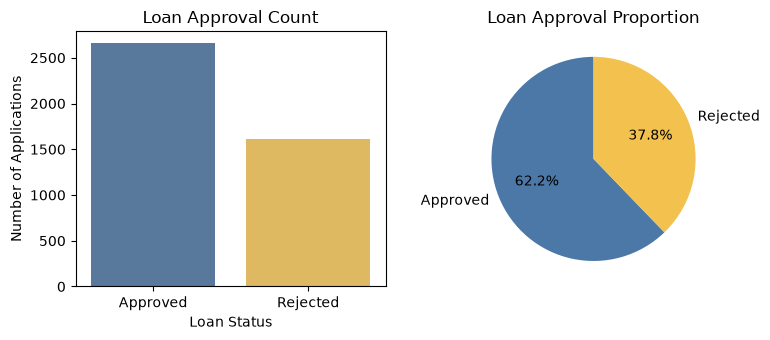

In [326]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

blue = "#4C78A8"
yellow = "#F2C14E"

# Bar chart
sns.countplot(
    data=df_cleaned,
    x="loan_status",
    hue="loan_status",
    palette={"Approved": blue, "Rejected": yellow},
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Loan Approval Count")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Number of Applications")

# Pie chart
status_counts = df_cleaned["loan_status"].value_counts()

axes[1].pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    colors=[blue, yellow],
    startangle=90
)

axes[1].set_title("Loan Approval Proportion")

plt.tight_layout()
plt.show()

#### 4.2 CIBIL Score and Loan Approval

CIBIL score is an important measure of creditworthiness. We compare the scores of approved and rejected applicants to identify differences between the two groups.

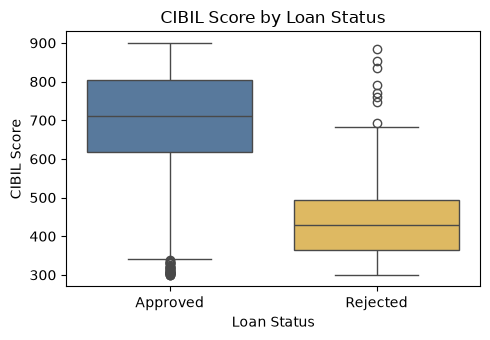

In [327]:
plt.figure(figsize=(5, 3.5))

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="cibil_score",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False
)

plt.title("CIBIL Score by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("CIBIL Score")
plt.tight_layout()
plt.show()

**Observation:** Approved applicants generally have higher CIBIL scores than rejected applicants. This suggests that CIBIL score may be an important predictor of loan approval.

#### 4.3 Income and Loan Amount

Income and loan amount are important financial factors. We compare them across loan outcomes to see whether they differ between approved and rejected applications.

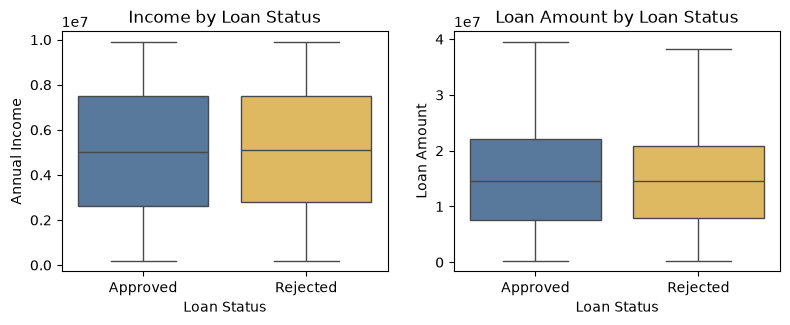

In [328]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="income_annum",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Income by Loan Status")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Annual Income")

sns.boxplot(
    data=df_cleaned,
    x="loan_status",
    y="loan_amount",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Loan Amount by Loan Status")
axes[1].set_xlabel("Loan Status")
axes[1].set_ylabel("Loan Amount")

plt.tight_layout()
plt.show()

**Observation:** The distributions show how income and requested loan amounts differ between approved and rejected applications.

#### 4.4 Applicant Characteristics

We compare education and self-employment status across loan outcomes to see whether approval varies between applicant groups.

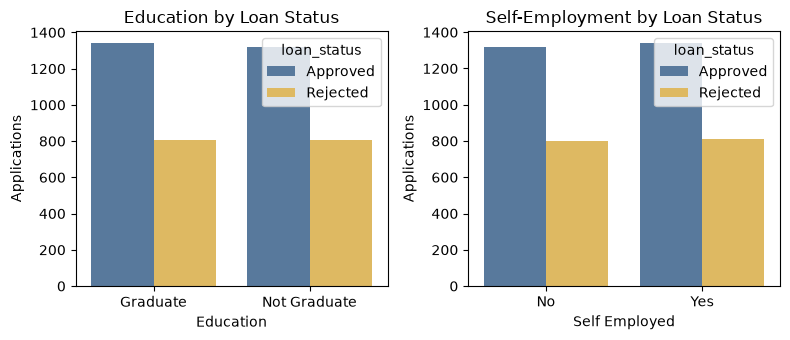

In [329]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

sns.countplot(
    data=df_cleaned,
    x="education",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    ax=axes[0]
)
axes[0].set_title("Education by Loan Status")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Applications")

sns.countplot(
    data=df_cleaned,
    x="self_employed",
    hue="loan_status",
    palette={"Approved": "#4C78A8", "Rejected": "#F2C14E"},
    ax=axes[1]
)
axes[1].set_title("Self-Employment by Loan Status")
axes[1].set_xlabel("Self Employed")
axes[1].set_ylabel("Applications")

plt.tight_layout()
plt.show()

#### 4.5 Correlation Between Numerical Features

We check the relationships between numerical features to identify variables that may contain similar information.

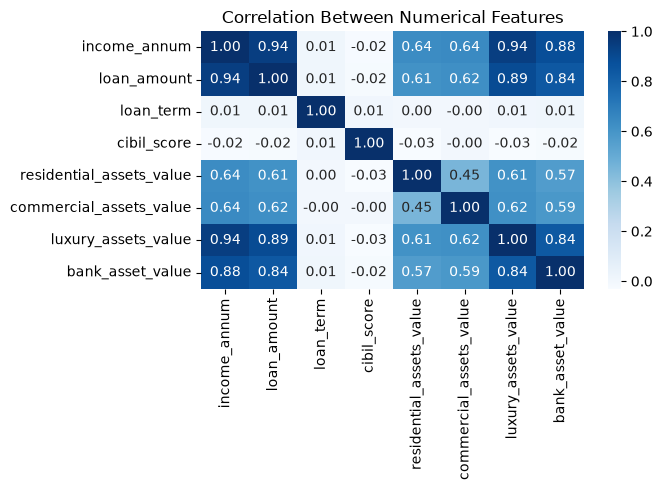

In [330]:
numeric_cols = [
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

plt.figure(figsize=(7, 5))

sns.heatmap(
    df_cleaned[numeric_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

#### EDA Summary

The EDA focused on loan-related factors such as CIBIL score, income, loan amount, education, and self-employment. These patterns will guide feature selection and preprocessing in the next step.

## Step 5: Data Preparation and Preprocessing

The exploratory analysis is complete, so the dataset is now prepared for machine learning.

The main goals of this step are to:

- Separate the predictors from the target variable.
- Exclude `loan_id`, since it is an identifier rather than a predictive feature.
- Split the data into training, validation, and test sets.
- Preserve the target-class proportions using stratified splitting.
- Build a preprocessing pipeline that handles missing values and categorical variables.
- Ensure that preprocessing is learned only from the training data to prevent data leakage.

The test set will remain untouched until the final evaluation in Step 9.

### 5.1 Define Features and Target

We separate the target variable, `loan_status`, from the predictor variables.

The `loan_id` column is also removed from the predictors because it uniquely identifies each application but does not represent an applicant characteristic.

The 28 invalid residential asset values were converted to missing values during cleaning. These values will be handled during preprocessing rather than manually calculated using the full dataset.

In [331]:
# ── Define features and target ─────────────────────────────

TARGET = "loan_status"

X = df_cleaned.drop(
    columns=[TARGET, "loan_id"]
)

y = df_cleaned[TARGET]

print(f"Features shape : {X.shape}")
print(f"Target shape   : {y.shape}")

print("\nTarget distribution:")
print(y.value_counts())

Features shape : (4269, 11)
Target shape   : (4269,)

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


### 5.2 Encoding the Target Variable

Machine learning models work with numerical target values, so the loan status is converted into binary labels.

- `Rejected` → `0`
- `Approved` → `1`

This encoding allows the models to treat the problem as binary classification.

In [332]:
# ── Encode target variable ─────────────────────────────────

target_mapping = {
    "Rejected": 0,
    "Approved": 1
}

y = y.map(target_mapping)

print("Encoded target values:")
print(y.value_counts().sort_index())

Encoded target values:
loan_status
0    1613
1    2656
Name: count, dtype: int64


### 5.3 Splitting the Dataset

The data is divided into training, validation, and test sets.

The training set is used to fit the models, the validation set is used to compare and tune models, and the test set is reserved for the final evaluation.

A 70/15/15 split provides enough data for training while keeping separate data for model selection and final evaluation.

Stratification is used so that the proportion of approved and rejected applications remains similar across the three sets.

In [333]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (2988, 11)
Validation: (640, 11)
Test: (641, 11)


### 5.4 Identifying Numerical and Categorical Features

The dataset contains both numerical and categorical variables, so they require different preprocessing.

Numerical variables will be imputed and scaled, while categorical variables will be imputed and one-hot encoded.

The feature types are identified from the training data so that the preprocessing can be applied consistently later.

In [334]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical features: ['education', 'self_employed']


C:\Users\Minn Bern\AppData\Local\Temp\ipykernel_10080\2272986216.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include="object").columns.tolist()


### 5.5 Building the Preprocessing Pipeline

The preprocessing steps are placed inside a pipeline so that they are applied consistently during model training and evaluation.

For numerical features:

- Missing values are replaced using the median.
- Values are standardized using `StandardScaler`.

For categorical features:

- Missing values are replaced using the most frequent category.
- Categories are converted into numerical columns using one-hot encoding.

The preprocessing will be fitted using the training data only. This helps prevent information from the validation or test sets from influencing the model.

In [335]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)


Training processed shape: (2988, 13)
Validation processed shape: (640, 13)


### Step 5 Summary

The cleaned dataset has been prepared for machine learning.

- The target variable was separated and encoded as binary values.
- `loan_id` was excluded because it is only an identifier.
- The data was divided into training, validation, and test sets using stratification.
- Numerical and categorical features were identified separately.
- A preprocessing pipeline was created for imputation, scaling, and categorical encoding.
- The preprocessing was fitted using the training data to reduce the risk of data leakage.

The data is now ready for baseline model development in Step 6.

## 6.1 Baseline Models

Three classification models are trained as initial benchmarks.

Each model uses the same preprocessing pipeline so that the comparison is fair. No hyperparameter tuning is performed yet.

In [336]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    pipeline.fit(X_train, y_train)
    
    results[name] = pipeline
    
print("Baseline models trained successfully.")

Baseline models trained successfully.


### 6.2 Baseline Evaluation

The models are evaluated on the validation set using accuracy, precision, recall, and F1-score.

These metrics provide different views of model performance and will help identify which baseline is most promising for further tuning.

In [337]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_results = []

for name, pipeline in results.items():
    y_pred = pipeline.predict(X_val)
    
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred)
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.92,0.93,0.93,0.93
1,Decision Tree,0.97,0.98,0.98,0.98
2,Random Forest,0.99,0.99,0.99,0.99


## Class Imbalance and Error Analysis
### 7.1 Class Distribution

Before interpreting model errors, we check the balance between approved and rejected applications.

This helps determine whether accuracy alone is sufficient for comparing the models.

In [338]:
print(y_train.value_counts())
print()
print((y_train.value_counts(normalize=True) * 100).round(2))

loan_status
1    1859
0    1129
Name: count, dtype: int64

loan_status
1   62.22
0   37.78
Name: proportion, dtype: float64


### 7.2 Confusion Matrices

A confusion matrix shows the types of predictions each model gets right and wrong.

It helps us see whether a model is more likely to incorrectly approve rejected applications or incorrectly reject approved applications.

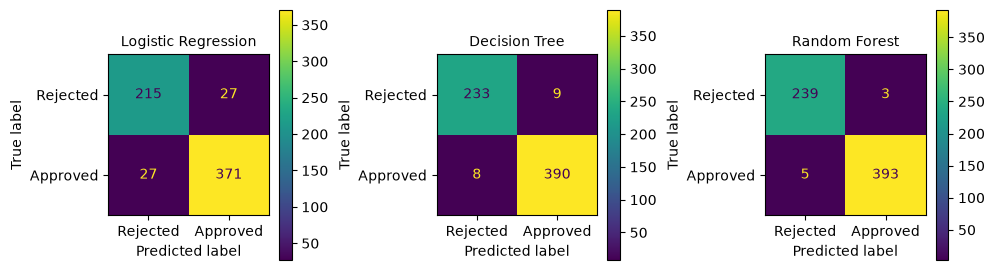

In [339]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, (name, pipeline) in zip(axes, results.items()):
    y_pred = pipeline.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        display_labels=["Rejected", "Approved"],
        ax=ax
    )
    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

### 7.3 Error Analysis

The confusion matrices help identify the main types of classification errors.

For loan approval, both false approvals and false rejections matter. Therefore, accuracy should be considered alongside precision, recall, and F1-score when selecting a model for further tuning.

In [340]:
from sklearn.metrics import classification_report

for name, pipeline in results.items():
    y_pred = pipeline.predict(X_val)
    
    print(f"\n{name}")
    print(classification_report(
        y_val,
        y_pred,
        target_names=["Rejected", "Approved"]
    ))


Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.89      0.89      0.89       242
    Approved       0.93      0.93      0.93       398

    accuracy                           0.92       640
   macro avg       0.91      0.91      0.91       640
weighted avg       0.92      0.92      0.92       640


Decision Tree
              precision    recall  f1-score   support

    Rejected       0.97      0.96      0.96       242
    Approved       0.98      0.98      0.98       398

    accuracy                           0.97       640
   macro avg       0.97      0.97      0.97       640
weighted avg       0.97      0.97      0.97       640


Random Forest
              precision    recall  f1-score   support

    Rejected       0.98      0.99      0.98       242
    Approved       0.99      0.99      0.99       398

    accuracy                           0.99       640
   macro avg       0.99      0.99      0.99       640
weighted avg       0.99

### Step 7 Summary

The class distribution and model errors have been examined using class proportions, confusion matrices, and classification metrics.

The validation results will be used to identify the most promising baseline model for hyperparameter tuning in Step 8.

The test set remains untouched.

### 8.1 Tuning the models

Hyperparameter tuning searches for better model settings without changing the underlying algorithm. We use 5-fold cross-validation on the training data, while the validation set remains separate for comparison. The test set is still untouched.

In [341]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter combinations for each model
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
    },
    
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10]
    },
    
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    }
}

# Store the tuned models
tuned_models = {}

# Tune each model
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=1
    )

    grid.fit(X_train, y_train)

    tuned_models[name] = grid

    print(f"{name} tuning completed.")
    print(f"Best parameters: {grid.best_params_}")
    print(f"Best CV F1 Score: {grid.best_score_:.3f}")
    print()

print("Hyperparameter tuning completed successfully.")

Logistic Regression tuning completed.
Best parameters: {'model__C': 0.1}
Best CV F1 Score: 0.932

Decision Tree tuning completed.
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2}
Best CV F1 Score: 0.980

Random Forest tuning completed.
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1 Score: 0.980

Hyperparameter tuning completed successfully.


In [342]:
tuned_results = []

for name, grid in tuned_models.items():
    y_pred = grid.predict(X_val)

    tuned_results.append({
        "Model": name,
        "CV F1": grid.best_score_,
        "Validation Accuracy": accuracy_score(y_val, y_pred),
        "Validation Precision": precision_score(y_val, y_pred),
        "Validation Recall": recall_score(y_val, y_pred),
        "Validation F1": f1_score(y_val, y_pred)
    })

tuned_df = pd.DataFrame(tuned_results)

display(tuned_df.round(3))

,Model,CV F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Logistic Regression,0.93,0.92,0.93,0.94,0.94
1,Decision Tree,0.98,0.97,0.98,0.98,0.98
2,Random Forest,0.98,0.98,0.99,0.98,0.99


In [343]:
for name, grid in tuned_models.items():
    print(f"{name}:")
    print(grid.best_params_)
    print()

Logistic Regression:
{'model__C': 0.1}

Decision Tree:
{'model__max_depth': None, 'model__min_samples_split': 2}

Random Forest:
{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}



In [344]:
#Select the best model using F1 validation score
best_model_name = tuned_df.loc[tuned_df["Validation F1"].idxmax(), "Model"]

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


## Step 9 — Final Evaluation

Now we choose the best tuned model based on the validation results and evaluate it once on the untouched test set.

In [345]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_prob)

print("FINAL TEST RESULTS")
print(f"Accuracy : {test_accuracy:.3f}")
print(f"Precision: {test_precision:.3f}")
print(f"Recall   : {test_recall:.3f}")
print(f"F1 Score : {test_f1:.3f}")
print(f"ROC-AUC  : {test_auc:.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Rejected", "Approved"]
))

FINAL TEST RESULTS
Accuracy : 0.981
Precision: 0.987
Recall   : 0.982
F1 Score : 0.985
ROC-AUC  : 0.999

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.97      0.98      0.98       242
    Approved       0.99      0.98      0.98       399

    accuracy                           0.98       641
   macro avg       0.98      0.98      0.98       641
weighted avg       0.98      0.98      0.98       641



#### 9.2 Validation vs Test

Comparing validation and test performance helps check whether the model generalizes well to unseen data. Similar results suggest that the model has not strongly overfit the validation set.

In [346]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Validation": [
        accuracy_score(y_val, best_model.predict(X_val)),
        precision_score(y_val, best_model.predict(X_val)),
        recall_score(y_val, best_model.predict(X_val)),
        f1_score(y_val, best_model.predict(X_val)),
        roc_auc_score(y_val, best_model.predict_proba(X_val)[:, 1])
    ],
    "Test": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

display(comparison.round(3))

,Metric,Validation,Test
0,Accuracy,0.98,0.98
1,Precision,0.99,0.99
2,Recall,0.98,0.98
3,F1,0.99,0.98
4,ROC-AUC,1.00,1.00


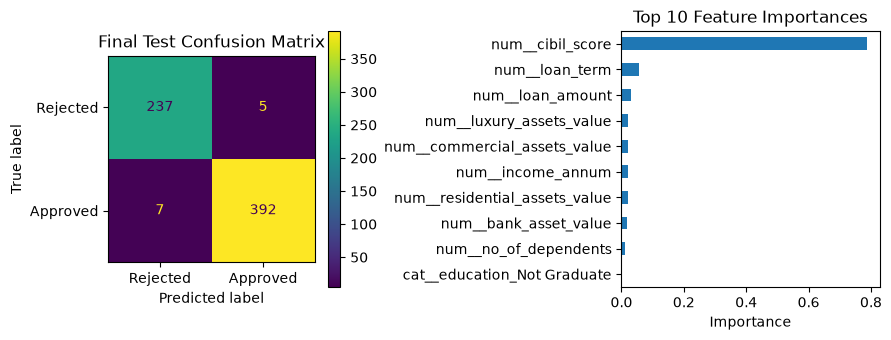

In [347]:
# The confusion matrix shows the types of loan decisions the model gets right and wrong. Feature importance helps identify which variables contribute most to the model's predictions.

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Rejected", "Approved"],
    ax=axes[0]
)
axes[0].set_title("Final Test Confusion Matrix")

# Feature importance
feature_importance = pd.Series(
    best_model.best_estimator_.named_steps["model"].feature_importances_,
    index=best_model.best_estimator_.named_steps["preprocessor"].get_feature_names_out()
).sort_values(ascending=False).head(10)

feature_importance.sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Top 10 Feature Importances")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.show()

### Final Model Summary

The best-performing model was selected using validation performance and evaluated on the untouched test set. The final metrics indicate how well the model generalizes to unseen loan applications. Feature importance provides additional insight into the factors influencing predictions.

In [348]:
display(tuned_df.sort_values("Validation F1", ascending=False))

,Model,CV F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
2,Random Forest,0.98,0.98,0.99,0.98,0.99
1,Decision Tree,0.98,0.97,0.98,0.98,0.98
0,Logistic Regression,0.93,0.92,0.93,0.94,0.93


Random Forest was selected as the final model because it achieved the highest validation F1 score (0.99), outperforming the Decision Tree (0.98) and Logistic Regression (0.93).

In [349]:
import joblib
import json

joblib.dump(best_model, "final_model.pkl")

final_config = {
    "model": best_model_name,
    "best_params": best_model.best_params_,
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "test_auc": float(test_auc)
}

with open("final_config.json", "w") as f:
    json.dump(final_config, f, indent=2)

print("Final model and configuration saved.")

Final model and configuration saved.
